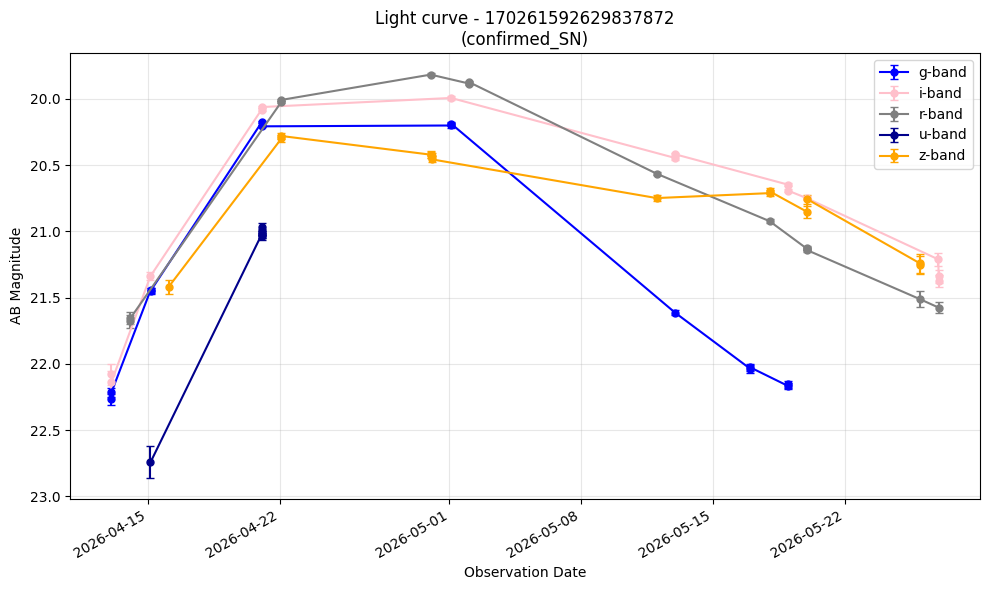

In [2]:
from light_curve_plotter import collect_light_curve_data, lightcurve_plotting
from pathlib import Path

csv_file = Path(r"C:\Users\riley\Documents\University\Honours\Honours_Project\data\Confirmed_SN\confirmed_SN.csv")
SN_ia_candidate = "170261592629837872"
df_lc = collect_light_curve_data(SN_ia_candidate)
lightcurve_plotting(df_lc, SN_ia_candidate, csv_file.stem)

['extragalactic\nlt20mag', 'extragalactic\nnew', 'sn near\ngalaxy']


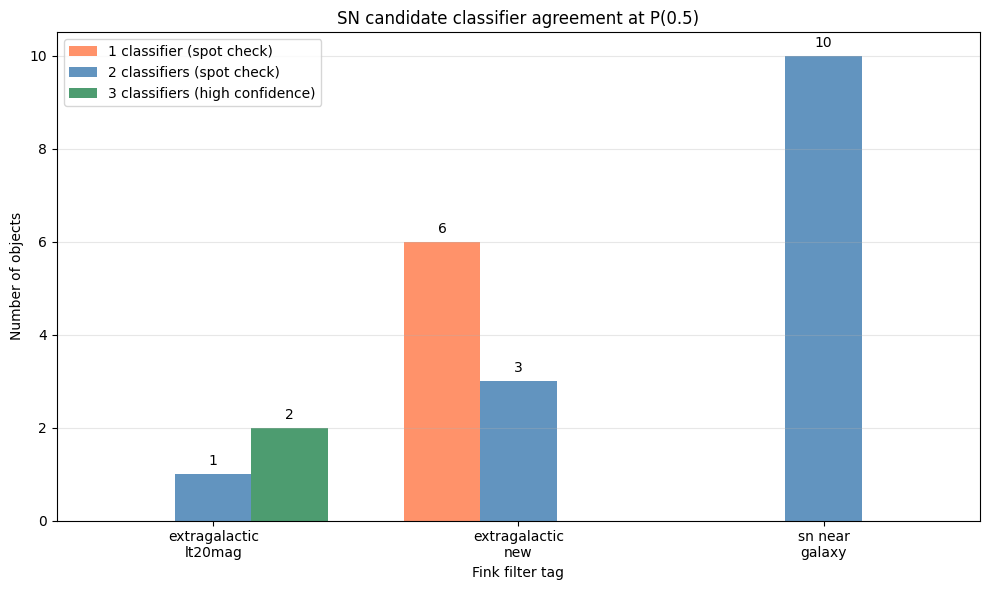

In [ ]:
# generated using Claude Sonnet 4.6 adaptive with the following prompt: "Now with the objects and their classification scores, 
# could you help me generate a plot that shows the number of objects from the acquisition pipeline that passed three, two or one classifier score cuts please?"

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

base_classified_path = Path(r"C:\Users\riley\Documents\University\Honours\Honours_Project\data\extragalactic_object_classified")
classified_csv_files = {
    "extragalactic\nlt20mag":    base_classified_path / "extragalactic_lt20mag_candidates_classified.csv",
    "extragalactic\nnew":        base_classified_path / "extragalactic_new_candidate_classified.csv",
    "sn near\ngalaxy":           base_classified_path / "sn_near_galaxy_candidate_classified.csv",
}

threshold = 0.5

# Count objects per tier per filter
tier_counts = {label: {1: 0, 2: 0, 3: 0} for label in classified_csv_files}

for label, path in classified_csv_files.items():
    df = pd.read_csv(path, dtype={"r:diaObjectId": str})

    mask_CATS      = (df["clf_cats_class_mode"] == 11) & (df["clf_cats_score_max"] > threshold)
    mask_EarlySNIa = df["clf_earlySNIa_max"] > threshold
    mask_snn       = df["clf_snn_max"] > threshold

    df_candidates = df[mask_CATS | mask_EarlySNIa | mask_snn].copy()
    df_candidates["n_classifiers_agree"] = (
        (df_candidates["clf_cats_score_max"] > threshold).astype(int) +
        (df_candidates["clf_earlySNIa_max"]  > threshold).astype(int) +
        (df_candidates["clf_snn_max"]        > threshold).astype(int)
    )

    for tier in [1, 2, 3]:
        tier_counts[label][tier] = len(df_candidates[df_candidates["n_classifiers_agree"] == tier])

# Plot
labels = list(tier_counts.keys())
n1 = [tier_counts[l][1] for l in labels]
n2 = [tier_counts[l][2] for l in labels]
n3 = [tier_counts[l][3] for l in labels]

x = np.arange(len(labels))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 6))

bars1 = ax.bar(x - width, n1, width, label="1 classifier (spot check)", color="coral",    alpha=0.85)
bars2 = ax.bar(x,          n2, width, label="2 classifiers (spot check)", color="steelblue", alpha=0.85)
bars3 = ax.bar(x + width,  n3, width, label="3 classifiers (high confidence)", color="seagreen", alpha=0.85)

# Add count labels on top of each bar
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        if height > 0:
            ax.annotate(f"{int(height)}",
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 4), textcoords="offset points",
                ha="center", va="bottom", fontsize=10)

ax.set_xlabel("Fink filter tag")
ax.set_ylabel("Number of objects")
ax.set_title(f"SN candidate classifier agreement at P({threshold})")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()
ax.grid(True, alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig("classifier_agreement.png", dpi=150)
plt.show()

In [2]:
import pandas as pd
from pathlib import Path

base_path = Path(r"C:\Users\riley\Documents\University\Honours\Honours_Project\data\Potential_SN_candidates")
rejects = Path(r"C:\Users\riley\Documents\University\Honours\Honours_Project\data\rejection_list.csv")
SN_candidates = Path(r"C:\Users\riley\Documents\University\Honours\Honours_Project\data\Confirmed_SN\confirmed_SN.csv")
SN_candidate_IDs = pd.read_csv(SN_candidates)["r:diaObjectId"]
reject_ids = pd.read_csv(rejects)["r:diaObjectId"]
classified_object_files = [base_path / "extragalactic_lt20mag_candidates_classified_spot_check_required_n_1.csv", 
                    base_path / "extragalactic_lt20mag_candidates_classified_spot_check_required_n_2.csv",
                    base_path / "extragalactic_lt20mag_candidates_classified_high_confidence.csv",
                    base_path / "extragalactic_new_candidate_classified_spot_check_required_n_1.csv",
                    base_path / "extragalactic_new_candidate_classified_spot_check_required_n_2.csv",
                    base_path / "extragalactic_new_candidate_classified_high_confidence.csv",
                    base_path / "sn_near_galaxy_candidate_classified_spot_check_required_n_1.csv",
                    base_path / "sn_near_galaxy_candidate_classified_spot_check_required_n_2.csv",
                    base_path / "sn_near_galaxy_candidate_classified_high_confidence.csv"]

for path in classified_object_files:
    df = pd.read_csv(path)
    filtered_df = df[~df["r:diaObjectId"].isin(reject_ids)]
    filtered_df = df[~df["r:diaObjectId"].isin(SN_candidate_IDs)]
    filtered_df.to_csv(path, index=False)